## 0. Налаштування середовища

In [12]:
import os, sys, random, textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import (train_test_split, cross_validate, KFold,
                                     learning_curve, validation_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             RocCurveDisplay, PrecisionRecallDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.calibration import CalibrationDisplay

warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42                       # Reproducible random seed
random.seed(SEED); np.random.seed(SEED)

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# Colorblind-friendly palette
PALETTE = sns.color_palette("colorblind", 6)
sns.set_palette(PALETTE)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def wrap(text, width=62):
    return "\n".join(textwrap.wrap(text, width))

def save_fig(fig, name):
    """Save a figure as a high-resolution PNG."""
    path = os.path.join(FIG_DIR, f"{name}.png")
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print("збережено:", path)

print("Python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", matplotlib.__version__)
print("seaborn     ", sns.__version__)
print("scikit-learn", sklearn.__version__)

Python       3.10.16
numpy        2.2.6
pandas       2.2.3
matplotlib   3.10.0
seaborn      0.13.2
scikit-learn 1.6.1


## 0.1 Конфігурація та дані

Ціль регресії — `Price` (AUD). Бінарна ціль `high_price` визначається за медіаною ціни. `Date` перетворюється на рік і місяць продажу. `Address` і цільова ціна не є ознаками. Пропуски в ознаках обробляються всередині pipeline.


In [13]:
# Configuration
DATA_PATH   = "Melbourne_housing_FULL.csv"
TARGET_CLF  = "high_price"
TARGET_REG  = "Price"
DATE_COL    = "Date"
NUM_COLS    = ["Rooms", "Distance", "Postcode", "Bedroom2", "Bathroom", "Car", "Landsize", "BuildingArea", "YearBuilt", "Lattitude", "Longtitude", "Propertycount", "SaleYear", "SaleMonth"]
CAT_COLS    = ["Suburb", "Type", "Method", "SellerG", "CouncilArea", "Regionname"]
COL_DIST, COL_CAT = "Distance", "Regionname"
COL_SC_X, COL_SC_Y, COL_SC_HUE = "Landsize", "Price", "Type"
LABELS = {"Price":"Ціна продажу, AUD", "high_price":"Ціна ≥ медіани (1 = так)", "Rooms":"Кімнати, шт", "Distance":"Відстань до центру, км", "Postcode":"Поштовий індекс", "Bedroom2":"Спальні, шт", "Bathroom":"Ванні кімнати, шт", "Car":"Паркомісця, шт", "Landsize":"Площа ділянки, м²", "BuildingArea":"Площа будівлі, м²", "YearBuilt":"Рік побудови", "Lattitude":"Широта", "Longtitude":"Довгота", "Propertycount":"Кількість об'єктів у передмісті", "SaleYear":"Рік продажу", "SaleMonth":"Місяць продажу", "Suburb":"Передмістя", "Type":"Тип житла", "Method":"Спосіб продажу", "SellerG":"Агентство", "CouncilArea":"Муніципалітет", "Regionname":"Регіон"}
lab = lambda c: LABELS.get(c, c)

# Load and prepare the data
# Parse dates and label prices at or above the median.
df = pd.read_csv(DATA_PATH, low_memory=False)
df[DATE_COL] = pd.to_datetime(df[DATE_COL], dayfirst=True, errors="coerce")
df[TARGET_REG] = pd.to_numeric(df[TARGET_REG], errors="coerce")
df = df.dropna(subset=[TARGET_REG, DATE_COL]).copy()
df["SaleYear"] = df[DATE_COL].dt.year
df["SaleMonth"] = df[DATE_COL].dt.month
price_median = df[TARGET_REG].median()
df[TARGET_CLF] = (df[TARGET_REG] >= price_median).astype(int)
print("Розмір після очищення цілі:", df.shape)
print(f"Медіанна ціна: {price_median:,.0f} AUD")
print("Частка high_price=1:", round(df[TARGET_CLF].mean(), 3))
df.head()


Розмір після очищення цілі: (27247, 24)
Медіанна ціна: 870,000 AUD
Частка high_price=1: 0.503


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,...,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount,SaleYear,SaleMonth,high_price
1,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,2016-12-03,2.5,3067.0,...,NaN,NaN,Yarra City Council,-37.7996,144.9984,Northern Metropolitan,4019.0,2016,12,1
2,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,2016-02-04,2.5,3067.0,...,79.0,1900.0,Yarra City Council,-37.8079,144.9934,Northern Metropolitan,4019.0,2016,2,1
4,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,2017-03-04,2.5,3067.0,...,150.0,1900.0,Yarra City Council,-37.8093,144.9944,Northern Metropolitan,4019.0,2017,3,1
5,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,2017-03-04,2.5,3067.0,...,NaN,NaN,Yarra City Council,-37.7969,144.9969,Northern Metropolitan,4019.0,2017,3,0
6,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,2016-06-04,2.5,3067.0,...,142.0,2014.0,Yarra City Council,-37.8072,144.9941,Northern Metropolitan,4019.0,2016,6,1


In [14]:
X = df[NUM_COLS + CAT_COLS]
y = df[TARGET_CLF].astype(int)
y_reg = df[TARGET_REG]

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)

for name, part in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:<11} n={len(part):>5}  частка high_price=1 = {part.mean():.3f}")

def make_pre():
    """Impute missing values, scale numeric features, and encode categories."""
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUM_COLS),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                           ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CAT_COLS),
    ])


train       n=16347  частка high_price=1 = 0.503
validation  n= 5450  частка high_price=1 = 0.503
test        n= 5450  частка high_price=1 = 0.503


---
# Результат 1. Панель візуалізації

Шість типів діаграм: **розподіл, порівняння категорій, залежність, часова, кореляції, багатовимірна**.  
Кожна має заголовок-висновок («що ми бачимо»), підписані осі з одиницями; без 3D; палітра ≤ 6 кольорів; стовпчики — з нуля.

> Заголовки тут формуються з обчислених чисел, тому відповідають даним. Якщо підставите свій набір — перечитайте кожен і переконайтесь, що висновок справді правдивий.

збережено: figures\01_distribution.png


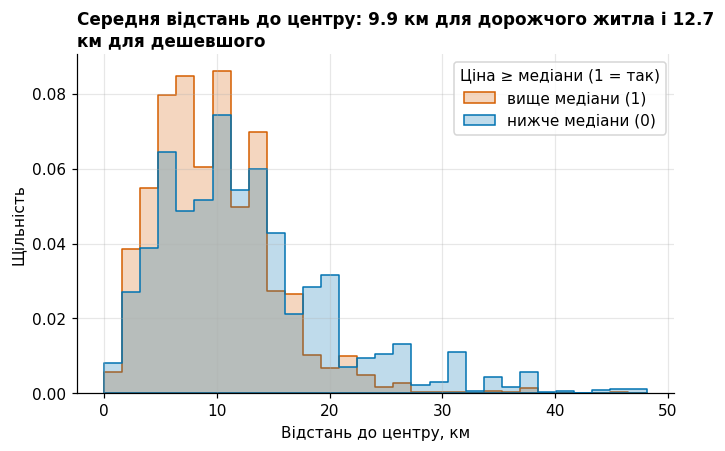

In [15]:
# 1.1 Distance distribution by price class
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=df, x=COL_DIST, hue=TARGET_CLF, stat="density", common_norm=False, bins=30, element="step", ax=ax, palette=[PALETTE[0], PALETTE[3]])
m = df.groupby(TARGET_CLF)[COL_DIST].mean()
ax.set_title(wrap(f"Середня відстань до центру: {m[1]:.1f} км для дорожчого житла і {m[0]:.1f} км для дешевшого"))
ax.set_xlabel(lab(COL_DIST)); ax.set_ylabel("Щільність")
ax.legend(title=lab(TARGET_CLF), labels=["вище медіани (1)", "нижче медіани (0)"])
save_fig(fig, "01_distribution"); plt.show()


збережено: figures\02_bar_categories.png


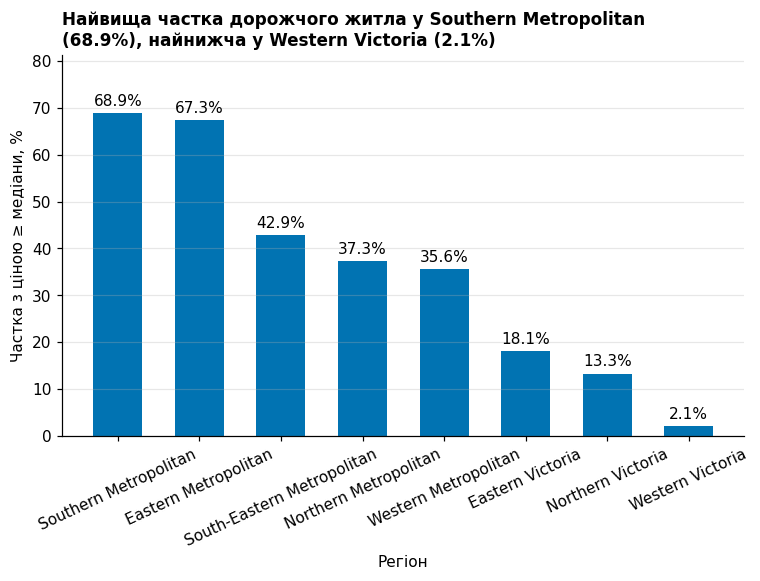

In [16]:
# 1.2 Share of higher-priced homes by region
g = (df.groupby(COL_CAT)[TARGET_CLF].mean() * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(g.index, g.values, color=PALETTE[0], width=0.6); ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_ylim(0, g.max() * 1.18); ax.set_title(wrap(f"Найвища частка дорожчого житла у {g.index[0]} ({g.iloc[0]:.1f}%), найнижча у {g.index[-1]} ({g.iloc[-1]:.1f}%)"))
ax.set_xlabel(lab(COL_CAT)); ax.set_ylabel("Частка з ціною ≥ медіани, %"); ax.tick_params(axis="x", rotation=25); ax.grid(axis="x", visible=False)
save_fig(fig, "02_bar_categories"); plt.show()


збережено: figures\03_scatter.png


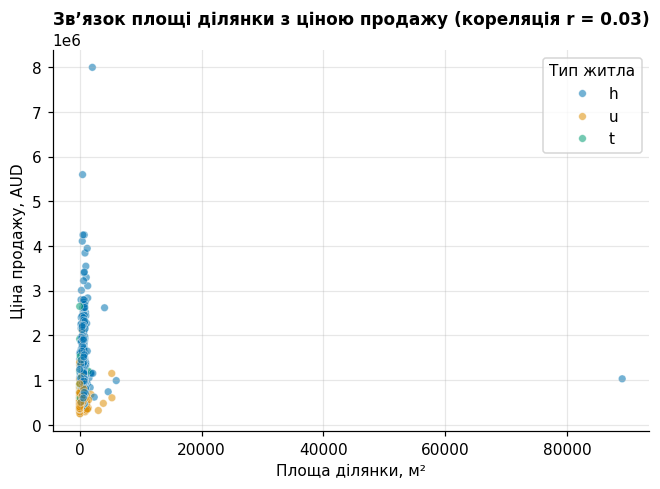

In [17]:
# 1.3 Land size and sale price
smp = df.sample(min(1200, len(df)), random_state=SEED)
r = df[[COL_SC_X, COL_SC_Y]].corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.scatterplot(data=smp, x=COL_SC_X, y=COL_SC_Y, hue=COL_SC_HUE, alpha=0.55, s=25, ax=ax)
ax.set_title(wrap(f"Зв’язок площі ділянки з ціною продажу (кореляція r = {r:.2f})"))
ax.set_xlabel(lab(COL_SC_X)); ax.set_ylabel(lab(COL_SC_Y)); ax.legend(title=lab(COL_SC_HUE))
save_fig(fig, "03_scatter"); plt.show()


збережено: figures\04_line_time.png


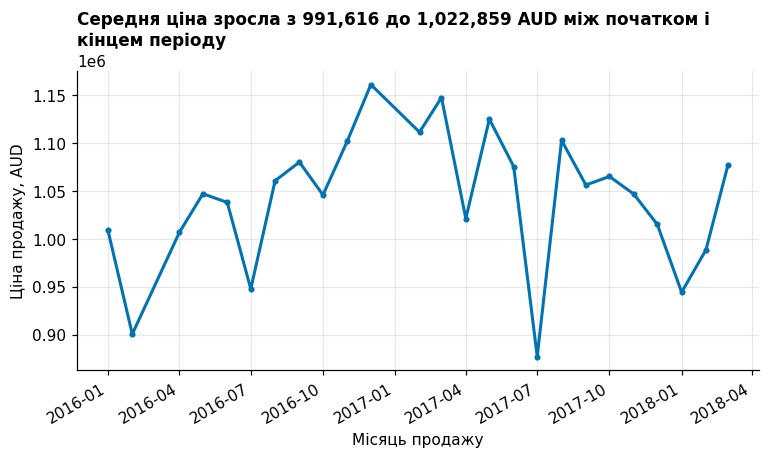

In [18]:
# 1.4 Average sale price over time
ts = df.set_index(DATE_COL)[TARGET_REG].resample("MS").mean().dropna()
a, b = ts.iloc[:6].mean(), ts.iloc[-6:].mean()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ts.index, ts.values, color=PALETTE[0], lw=2, marker="o", ms=3)
ax.set_title(wrap(f"Середня ціна {'зросла' if b > a else 'знизилася'} з {a:,.0f} до {b:,.0f} AUD між початком і кінцем періоду"))
ax.set_xlabel("Місяць продажу"); ax.set_ylabel(lab(TARGET_REG)); fig.autofmt_xdate()
save_fig(fig, "04_line_time"); plt.show()


збережено: figures\05_heatmap.png


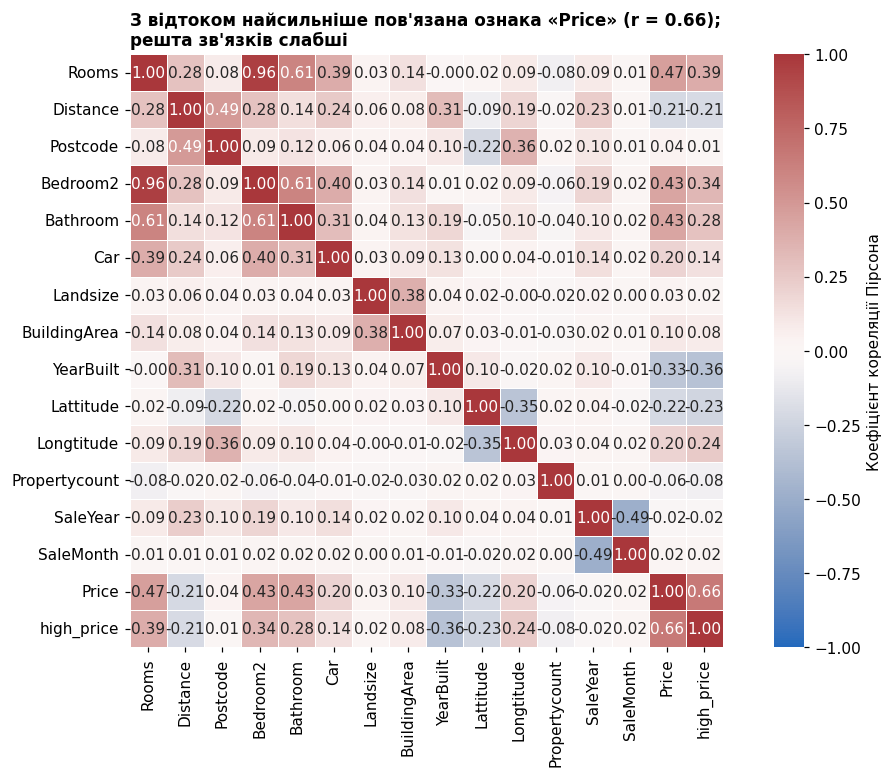

In [32]:
# 1.5 Correlation heatmap
corr = df[NUM_COLS + [TARGET_REG, TARGET_CLF]].corr()
top = corr[TARGET_CLF].drop(TARGET_CLF).abs().idxmax()
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={"label": "Коефіцієнт кореляції Пірсона"}, ax=ax)
ax.set_title(wrap(f"З відтоком найсильніше пов'язана ознака «{top}» "
                  f"(r = {corr.loc[top, TARGET_CLF]:.2f}); решта зв'язків слабші"))
ax.grid(False)
save_fig(fig, "05_heatmap"); plt.show()

збережено: figures\06_pairplot.png


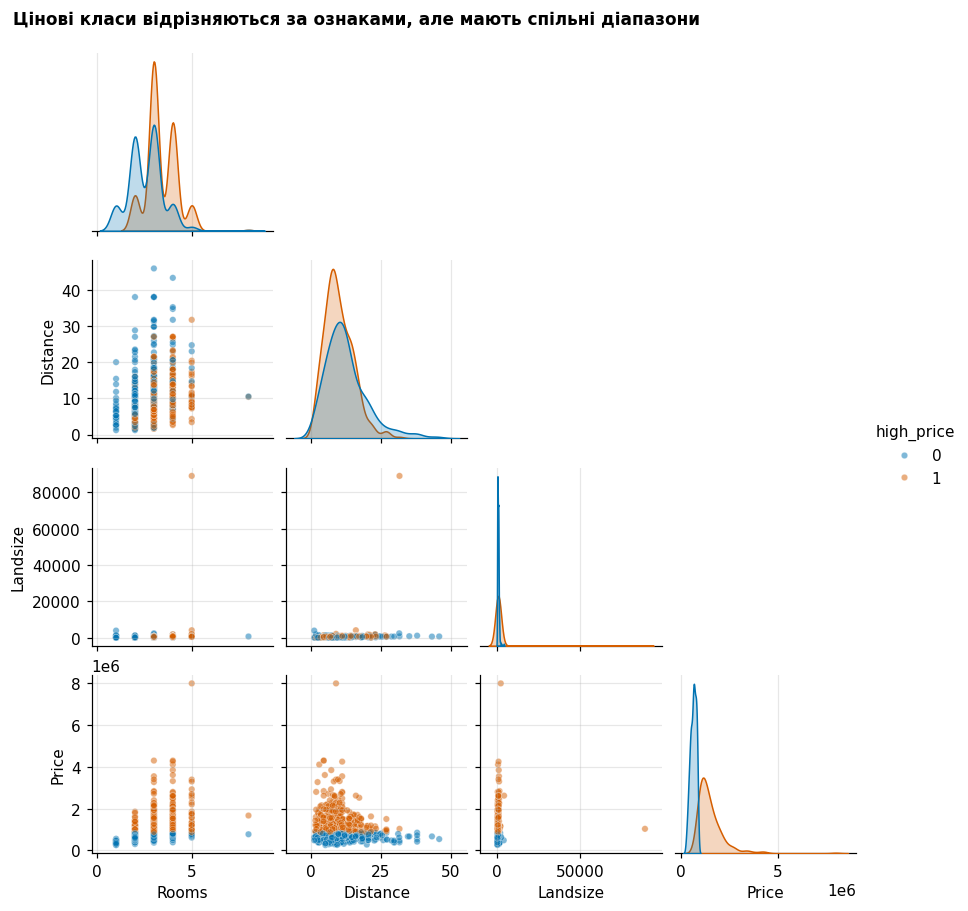

In [20]:
# 1.6 Numeric feature pairs by price class
cols_pp = ["Rooms", "Distance", "Landsize", TARGET_REG]
pp = sns.pairplot(df.sample(min(700, len(df)), random_state=SEED)[cols_pp + [TARGET_CLF]], hue=TARGET_CLF, palette=[PALETTE[0], PALETTE[3]], corner=True, plot_kws=dict(alpha=0.5, s=18), height=2.0)
pp.figure.suptitle("Цінові класи відрізняються за ознаками, але мають спільні діапазони", y=1.03, x=0.02, ha="left", fontweight="bold", fontsize=11)
save_fig(pp.figure, "06_pairplot"); plt.show()


### Погана діаграма → виправлена

Нижче навмисно зроблено **погану** версію діаграми з рис. 02 і поруч — виправлену.

збережено: figures\07_bad_vs_good.png


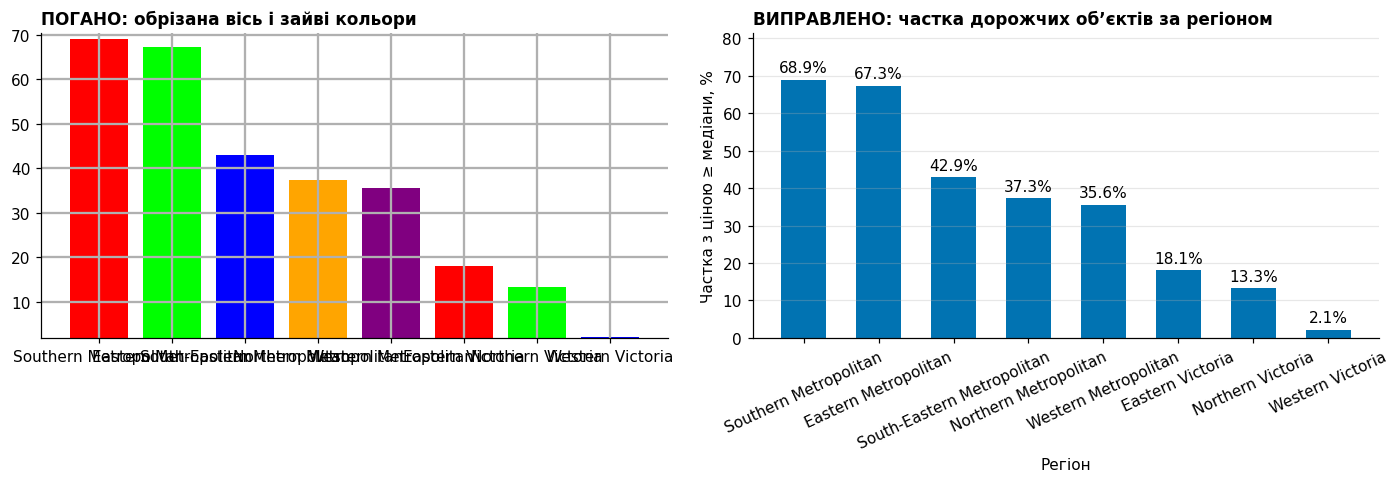

In [21]:
fig, (axb, axg) = plt.subplots(1, 2, figsize=(13, 4.5))
axb.bar(g.index, g.values, color=["red", "lime", "blue", "orange", "purple"][:len(g)])
axb.set_ylim(g.min() * 0.9, g.max() * 1.02); axb.set_title("ПОГАНО: обрізана вісь і зайві кольори"); axb.grid(True, alpha=1, lw=1.5)
bars = axg.bar(g.index, g.values, color=PALETTE[0], width=0.6); axg.bar_label(bars, fmt="%.1f%%", padding=3)
axg.set_ylim(0, g.max() * 1.18); axg.set_title("ВИПРАВЛЕНО: частка дорожчих об’єктів за регіоном")
axg.set_xlabel(lab(COL_CAT)); axg.set_ylabel("Частка з ціною ≥ медіани, %"); axg.tick_params(axis="x", rotation=25); axg.grid(axis="x", visible=False)
fig.tight_layout(); save_fig(fig, "07_bad_vs_good"); plt.show()


---
# Результат 2. Моделі класифікації та матриця помилок

Дві моделі (логістична регресія та RandomForest) і baseline (`DummyClassifier`). Позитивний клас — `high_price=1` (ціна не нижча за медіану). Метрики порівнюємо на validation і фінально оцінюємо на test.


In [22]:
models = {
    "Baseline (Dummy, prior)": DummyClassifier(strategy="prior"),
    "LogisticRegression": LogisticRegression(max_iter=1000, random_state=SEED),
    "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                           random_state=SEED, n_jobs=-1),
}
pipes = {n: Pipeline([("prep", make_pre()), ("model", m)]).fit(X_train, y_train)
         for n, m in models.items()}

proba_val  = {n: p.predict_proba(X_val)[:, 1]  for n, p in pipes.items()}
proba_test = {n: p.predict_proba(X_test)[:, 1] for n, p in pipes.items()}

def clf_metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "F1": f1_score(y_true, pred, zero_division=0)}

tab_val  = pd.DataFrame({n: clf_metrics(y_val,  proba_val[n])  for n in pipes}).T
tab_test = pd.DataFrame({n: clf_metrics(y_test, proba_test[n]) for n in pipes}).T

print("=== VALIDATION (поріг 0.5) ===");  display(tab_val.round(3))
print("=== TEST (поріг 0.5) ===");        display(tab_test.round(3))

real = [n for n in pipes if not n.startswith("Baseline")]
best_name = max(real, key=lambda n: tab_val.loc[n, "F1"])   # Select using validation data only
print("Найкраща модель за F1 на validation:", best_name)

=== VALIDATION (поріг 0.5) ===


,TN,FP,FN,TP,accuracy,precision,recall,F1
"Baseline (Dummy, prior)",0.0,2707.0,0.0,2743.0,0.503,0.503,1.000,0.670
LogisticRegression,2404.0,303.0,326.0,2417.0,0.885,0.889,0.881,0.885
RandomForest,2409.0,298.0,365.0,2378.0,0.878,0.889,0.867,0.878


=== TEST (поріг 0.5) ===


,TN,FP,FN,TP,accuracy,precision,recall,F1
"Baseline (Dummy, prior)",0.0,2707.0,0.0,2743.0,0.503,0.503,1.000,0.670
LogisticRegression,2409.0,298.0,301.0,2442.0,0.890,0.891,0.890,0.891
RandomForest,2408.0,299.0,325.0,2418.0,0.886,0.890,0.882,0.886


Найкраща модель за F1 на validation: LogisticRegression


збережено: figures\08_confusion_matrices.png


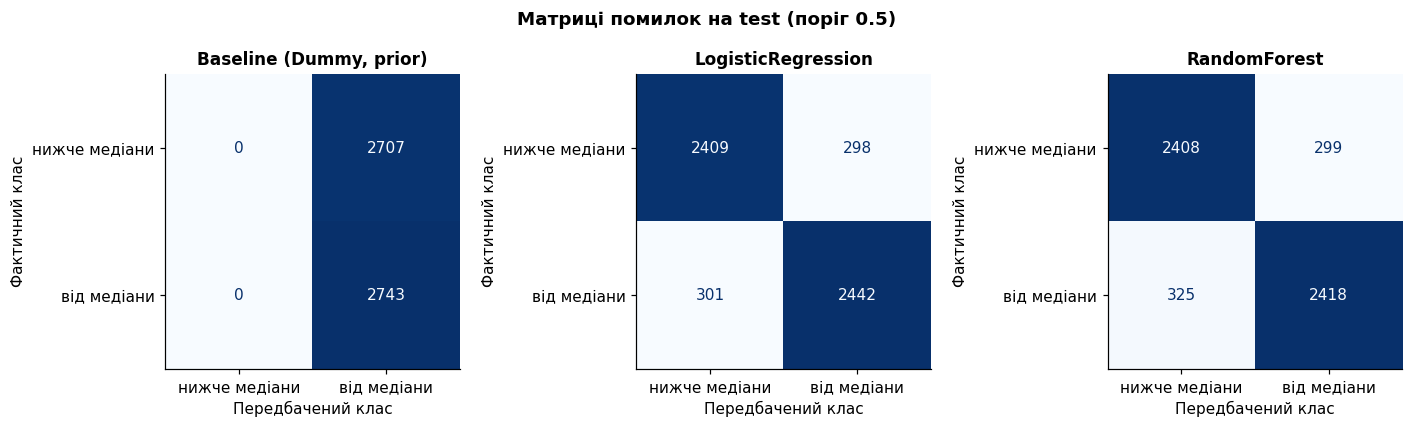

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, (n, p) in zip(axes, pipes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba_test[n] >= 0.5).astype(int), display_labels=["нижче медіани", "від медіани"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(n, loc="center"); ax.set_xlabel("Передбачений клас"); ax.set_ylabel("Фактичний клас"); ax.grid(False)
fig.suptitle("Матриці помилок на test (поріг 0.5)", fontweight="bold")
fig.tight_layout(); save_fig(fig, "08_confusion_matrices"); plt.show()


In [24]:
# Test summary
summary = tab_test[["accuracy", "precision", "recall", "F1"]].round(3)
display(summary)

acc_dummy = summary.loc["Baseline (Dummy, prior)", "accuracy"]
print(f"Baseline має accuracy = {acc_dummy:.3f}, хоча не знаходить жодного позитивного випадку "
      f"(recall = 0): це ілюстрація, чому accuracy оманлива за дисбалансу.")

,accuracy,precision,recall,F1
"Baseline (Dummy, prior)",0.503,0.503,1.000,0.670
LogisticRegression,0.890,0.891,0.890,0.891
RandomForest,0.886,0.890,0.882,0.886


Baseline має accuracy = 0.503, хоча не знаходить жодного позитивного випадку (recall = 0): це ілюстрація, чому accuracy оманлива за дисбалансу.


---
# Результат 3. ROC- та PR-криві, калібрування

Використовуємо `predict_proba` обох моделей на test. ROC показує якість ранжування незалежно від порога; PR — компроміс precision/recall для позитивного (рідкісного) класу.

збережено: figures\09_roc_pr.png


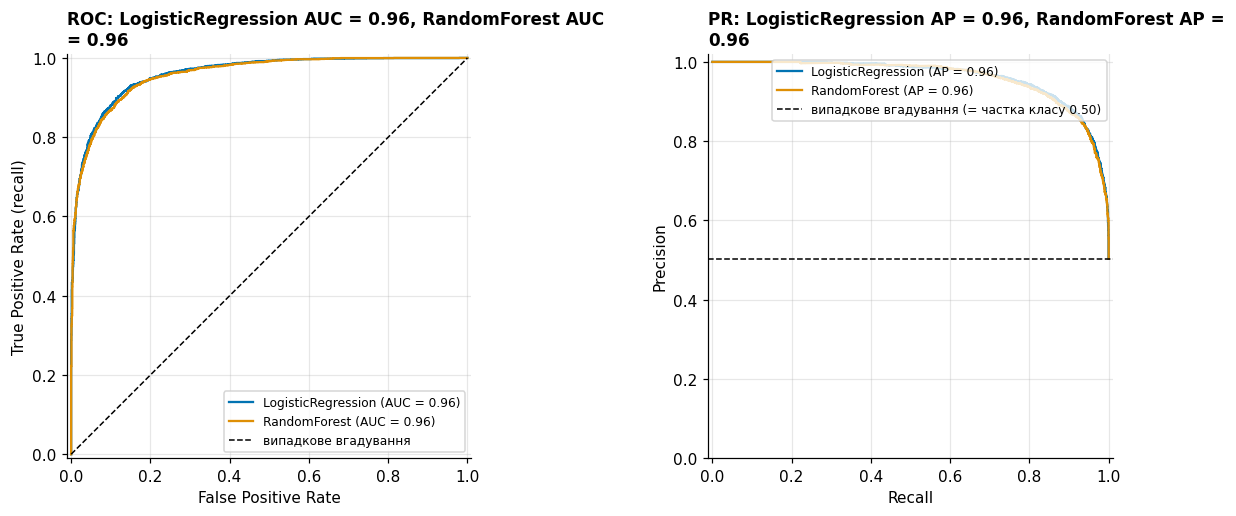

,ROC AUC,Average precision,baseline AP (частка класу)
LogisticRegression,0.960,0.963,0.503
RandomForest,0.958,0.961,0.503


In [25]:
two = real  # Exclude the dummy baseline
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

for i, n in enumerate(two):
    RocCurveDisplay.from_predictions(y_test, proba_test[n], name=n, ax=ax1)
    PrecisionRecallDisplay.from_predictions(y_test, proba_test[n], name=n, ax=ax2)
ax1.plot([0, 1], [0, 1], "k--", lw=1, label="випадкове вгадування")
ax2.axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"випадкове вгадування (= частка класу {y_test.mean():.2f})")

auc = {n: roc_auc_score(y_test, proba_test[n]) for n in two}
ap  = {n: average_precision_score(y_test, proba_test[n]) for n in two}
ax1.set_title(wrap("ROC: " + ", ".join(f"{n} AUC = {auc[n]:.2f}" for n in two), 52))
ax2.set_title(wrap("PR: " + ", ".join(f"{n} AP = {ap[n]:.2f}" for n in two), 52))
ax1.set_xlabel("False Positive Rate"); ax1.set_ylabel("True Positive Rate (recall)")
ax2.set_xlabel("Recall"); ax2.set_ylabel("Precision"); ax2.set_ylim(0, 1.02)
ax1.legend(loc="lower right", fontsize=8); ax2.legend(loc="upper right", fontsize=8)
fig.tight_layout()
save_fig(fig, "09_roc_pr"); plt.show()

display(pd.DataFrame({"ROC AUC": auc, "Average precision": ap, "baseline AP (частка класу)": y_test.mean()}).round(3))

збережено: figures\10_calibration.png


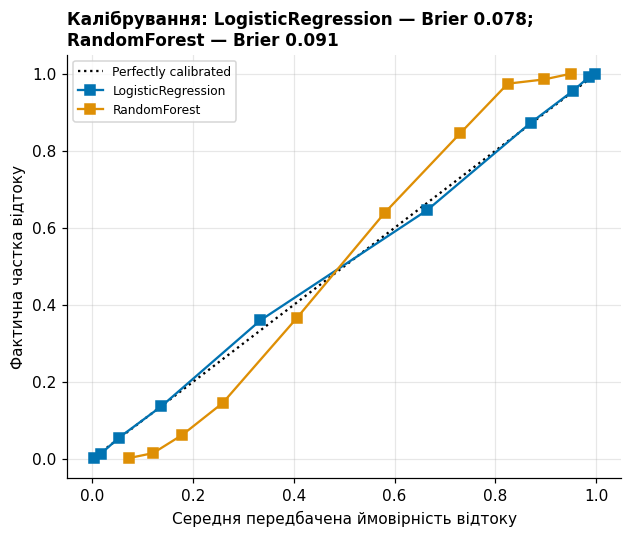

Brier score (менше = краще): {'LogisticRegression': np.float64(0.0783), 'RandomForest': np.float64(0.0907)}


In [26]:
# Calibration curve
fig, ax = plt.subplots(figsize=(6.5, 5))
for i, n in enumerate(two):
    CalibrationDisplay.from_predictions(y_test, proba_test[n], n_bins=10, strategy="quantile",
                                        name=n, ax=ax)
brier = {n: brier_score_loss(y_test, proba_test[n]) for n in two}
ax.set_title(wrap("Калібрування: " + "; ".join(f"{n} — Brier {brier[n]:.3f}" for n in two), 55))
ax.set_xlabel("Середня передбачена ймовірність відтоку"); ax.set_ylabel("Фактична частка відтоку")
ax.legend(loc="upper left", fontsize=8)
save_fig(fig, "10_calibration"); plt.show()
print("Brier score (менше = краще):", {k: round(v, 4) for k, v in brier.items()})

---
# Результат 4. Поріг за вартістю помилок

Працюємо з найкращою моделлю (вибрана за validation). Алгоритм:
1. Задаємо вартості FP і FN.
2. На **validation** рахуємо очікувані витрати для порогів 0.05…0.95.
3. Мінімум → поріг `t*`.
4. Фіксуємо `t*` і лише тоді дивимось на **test** — порівнюємо з порогом 0.5.

In [27]:
# Set assumed error costs
C_FP = 5_000                                           # Assumed cost of a false positive
C_FN = 25_000                                          # Assumed cost of a false negative
print(f"C_FP = {C_FP} AUD, C_FN = {C_FN:.0f} AUD (відношення FN:FP = {C_FN / C_FP:.1f}:1)")
print(f"Теоретичний поріг для ідеально відкаліброваних ймовірностей: {C_FP / (C_FP + C_FN):.3f}")

def total_cost(y_true, proba, thr, c_fp=C_FP, c_fn=C_FN):
    y_true = np.asarray(y_true); pred = np.asarray(proba) >= thr
    fp = int(((pred == 1) & (y_true == 0)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum())
    return fp * c_fp + fn * c_fn, fp, fn

best_val_proba  = proba_val[best_name]
best_test_proba = proba_test[best_name]

# Compare costs on validation data
thresholds = np.round(np.arange(0.05, 0.951, 0.05), 2)
rows = []
for t in thresholds:
    c, fp, fn = total_cost(y_val, best_val_proba, t)
    rows.append({"threshold": t, "FP": fp, "FN": fn, "cost": c, "cost_per_client": c / len(y_val)})
cost_val = pd.DataFrame(rows)

# Select the lowest-cost threshold
t_star = float(cost_val.loc[cost_val["cost"].idxmin(), "threshold"])
print(f"Оптимальний поріг на validation: t* = {t_star}")
display(cost_val.round(2))

C_FP = 5000 AUD, C_FN = 25000 AUD (відношення FN:FP = 5.0:1)
Теоретичний поріг для ідеально відкаліброваних ймовірностей: 0.167
Оптимальний поріг на validation: t* = 0.15


,threshold,FP,FN,cost,cost_per_client
0,0.05,1364,27,7495000,1375.23
1,0.10,997,58,6435000,1180.73
2,0.15,783,93,6240000,1144.95
3,0.20,671,116,6255000,1147.71
4,0.25,564,144,6420000,1177.98
5,0.30,484,182,6970000,1278.90
6,0.35,431,220,7655000,1404.59
7,0.40,387,259,8410000,1543.12
8,0.45,339,291,8970000,1645.87
9,0.50,303,326,9665000,1773.39


збережено: figures\11_cost_vs_threshold.png


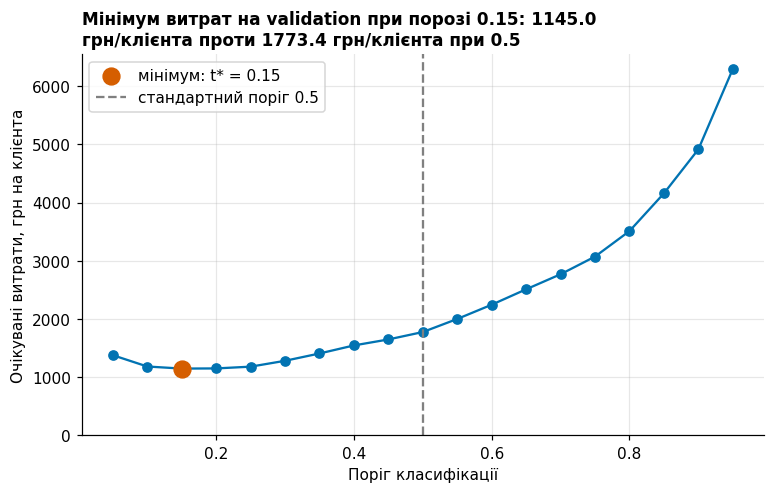

In [28]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(cost_val["threshold"], cost_val["cost_per_client"], marker="o", color=PALETTE[0])
c_star = cost_val.set_index("threshold").loc[t_star, "cost_per_client"]
c_05   = cost_val.set_index("threshold").loc[0.5, "cost_per_client"] if 0.5 in cost_val["threshold"].values else np.nan
ax.scatter([t_star], [c_star], s=120, color=PALETTE[3], zorder=5, label=f"мінімум: t* = {t_star:.2f}")
ax.axvline(0.5, color="gray", ls="--", label="стандартний поріг 0.5")
ax.set_ylim(0, None)
ax.set_title(wrap(f"Мінімум витрат на validation при порозі {t_star:.2f}: {c_star:.1f} грн/клієнта "
                  f"проти {c_05:.1f} грн/клієнта при 0.5"))
ax.set_xlabel("Поріг класифікації"); ax.set_ylabel("Очікувані витрати, грн на клієнта")
ax.legend()
save_fig(fig, "11_cost_vs_threshold"); plt.show()

In [29]:
# Evaluate the selected threshold on test data
res = []
for label, t in [(f"t* = {t_star:.2f} (з validation)", t_star), ("t = 0.50 (стандарт)", 0.5)]:
    c, fp, fn = total_cost(y_test, best_test_proba, t)
    m = clf_metrics(y_test, best_test_proba, t)
    res.append({"поріг": label, "FP": fp, "FN": fn, "precision": m["precision"], "recall": m["recall"],
                "F1": m["F1"], "витрати, AUD": c, "AUD/об’єкт": c / len(y_test)})
cmp_test = pd.DataFrame(res).set_index("поріг")
display(cmp_test.round(3))

saving = cmp_test.iloc[1]["витрати, грн"] - cmp_test.iloc[0]["витрати, грн"]
pct = 100 * saving / cmp_test.iloc[1]["витрати, грн"]
print(f"Економія на test: {saving:,.0f} грн ({pct:.1f}%) на {len(y_test)} клієнтів; "
      f"це {saving / len(y_test):.1f} грн на клієнта.")

,FP,FN,precision,recall,F1,"витрати, AUD",AUD/об’єкт
поріг,,,,,,,
t* = 0.15 (з validation),807,76,0.768,0.972,0.858,5935000,1088.991
t = 0.50 (стандарт),298,301,0.891,0.890,0.891,9015000,1654.128


KeyError: 'витрати, грн'

In [33]:
ytr, yva, yte = y_reg.loc[X_train.index], y_reg.loc[X_val.index], y_reg.loc[X_test.index]

reg_models = {
    "Baseline (Dummy, mean)": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(alpha=1.0, random_state=SEED),
    "RandomForestRegressor": RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                                   random_state=SEED, n_jobs=-1),
}
reg_pipes = {n: Pipeline([("prep", make_pre()), ("model", m)]).fit(X_train, ytr)
             for n, m in reg_models.items()}

def reg_metrics(y_true, pred):
    return {"MAE": mean_absolute_error(y_true, pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, pred)),
            "R2": r2_score(y_true, pred)}

reg_test = pd.DataFrame({n: reg_metrics(yte, p.predict(X_test)) for n, p in reg_pipes.items()}).T
print("=== TEST: регресія ===")
display(reg_test.round(3))

main_reg = "RandomForestRegressor"
print(f"RMSE >= MAE завжди; різниця більша, коли є великі поодинокі помилки "
      f"(RMSE штрафує великі відхилення квадратично). Тут RMSE/MAE = "
      f"{reg_test.loc[main_reg, 'RMSE'] / reg_test.loc[main_reg, 'MAE']:.2f}.")

=== TEST: регресія ===


,MAE,RMSE,R2
"Baseline (Dummy, mean)",453492.221,645790.290,-0.000
Ridge,229122.880,373324.605,0.666
RandomForestRegressor,169349.049,306609.318,0.775


RMSE >= MAE завжди; різниця більша, коли є великі поодинокі помилки (RMSE штрафує великі відхилення квадратично). Тут RMSE/MAE = 1.81.


### 5-кратна крос-валідація

CV робимо на **train + validation** (test лишається недоторканим). `KFold(5, shuffle=True, random_state=SEED)`.

In [34]:
X_tv = pd.concat([X_train, X_val]); y_tv = pd.concat([ytr, yva])
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

cv_rows = {}
for n, m in reg_models.items():
    pipe = Pipeline([("prep", make_pre()), ("model", m)])
    cv = cross_validate(pipe, X_tv, y_tv, cv=kf, scoring=scoring, return_train_score=True, n_jobs=-1)
    row = {}
    for k in ["MAE", "RMSE"]:
        row[f"{k} (val)"] = f"{-cv[f'test_{k}'].mean():.2f} ± {cv[f'test_{k}'].std():.2f}"
        row[f"{k} (train)"] = f"{-cv[f'train_{k}'].mean():.2f} ± {cv[f'train_{k}'].std():.2f}"
    row["R2 (val)"] = f"{cv['test_R2'].mean():.3f} ± {cv['test_R2'].std():.3f}"
    row["R2 (train)"] = f"{cv['train_R2'].mean():.3f} ± {cv['train_R2'].std():.3f}"
    cv_rows[n] = row
    if n == main_reg:
        cv_main = cv
cv_table = pd.DataFrame(cv_rows).T
print("Середнє ± σ по 5 фолдах (train+validation):")
display(cv_table)

Середнє ± σ по 5 фолдах (train+validation):


,MAE (val),MAE (train),RMSE (val),RMSE (train),R2 (val),R2 (train)
"Baseline (Dummy, mean)",452198.40 ± 9385.16,452156.97 ± 3016.60,640033.77 ± 22616.40,640340.89 ± 5666.65,-0.001 ± 0.000,0.000 ± 0.000
Ridge,231471.59 ± 5021.04,223565.90 ± 2292.11,378692.21 ± 24896.20,355623.94 ± 3337.99,0.648 ± 0.048,0.692 ± 0.002
RandomForestRegressor,167925.40 ± 4700.76,97054.10 ± 773.71,297941.41 ± 15365.05,184677.00 ± 2263.72,0.783 ± 0.013,0.917 ± 0.002


### Криві навчання та валідаційна крива

збережено: figures\12_learning_validation_curves.png


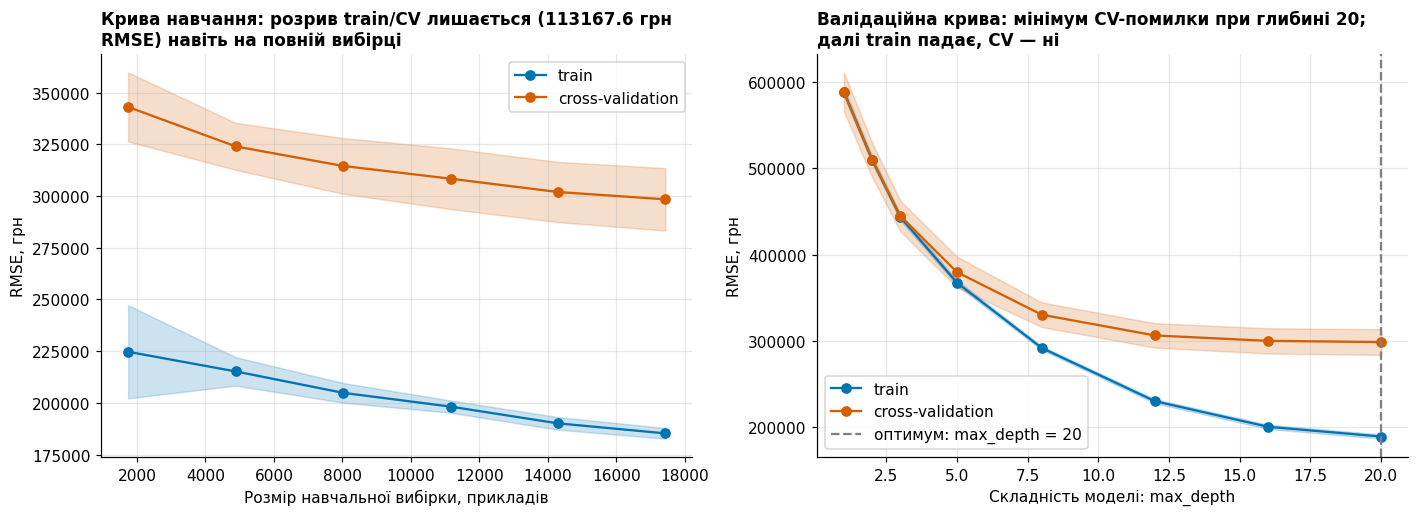

In [35]:
pipe_lc = Pipeline([("prep", make_pre()),
                    ("model", RandomForestRegressor(n_estimators=100, min_samples_leaf=3,
                                                    random_state=SEED, n_jobs=-1))])

# Learning curve by training set size
sizes, tr_sc, va_sc = learning_curve(pipe_lc, X_tv, y_tv, cv=kf, train_sizes=np.linspace(0.1, 1.0, 6),
                                     scoring="neg_root_mean_squared_error", n_jobs=-1, random_state=SEED)
tr_m, tr_s, va_m, va_s = -tr_sc.mean(1), tr_sc.std(1), -va_sc.mean(1), va_sc.std(1)

# Validation curve by tree depth
depths = [1, 2, 3, 5, 8, 12, 16, 20]
vtr, vva = validation_curve(pipe_lc, X_tv, y_tv, param_name="model__max_depth", param_range=depths,
                            cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
vtr_m, vtr_s, vva_m, vva_s = -vtr.mean(1), vtr.std(1), -vva.mean(1), vva.std(1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.plot(sizes, tr_m, "o-", color=PALETTE[0], label="train")
ax1.fill_between(sizes, tr_m - tr_s, tr_m + tr_s, color=PALETTE[0], alpha=0.2)
ax1.plot(sizes, va_m, "o-", color=PALETTE[3], label="cross-validation")
ax1.fill_between(sizes, va_m - va_s, va_m + va_s, color=PALETTE[3], alpha=0.2)
ax1.set_title(wrap(f"Крива навчання: розрив train/CV лишається ({va_m[-1] - tr_m[-1]:.1f} грн RMSE) "
                   f"навіть на повній вибірці", 55))
ax1.set_xlabel("Розмір навчальної вибірки, прикладів"); ax1.set_ylabel("RMSE, грн"); ax1.legend()

ax2.plot(depths, vtr_m, "o-", color=PALETTE[0], label="train")
ax2.fill_between(depths, vtr_m - vtr_s, vtr_m + vtr_s, color=PALETTE[0], alpha=0.2)
ax2.plot(depths, vva_m, "o-", color=PALETTE[3], label="cross-validation")
ax2.fill_between(depths, vva_m - vva_s, vva_m + vva_s, color=PALETTE[3], alpha=0.2)
best_d = depths[int(np.argmin(vva_m))]
ax2.axvline(best_d, color="gray", ls="--", label=f"оптимум: max_depth = {best_d}")
ax2.set_title(wrap(f"Валідаційна крива: мінімум CV-помилки при глибині {best_d}; "
                   f"далі train падає, CV — ні", 55))
ax2.set_xlabel("Складність моделі: max_depth"); ax2.set_ylabel("RMSE, грн"); ax2.legend()
fig.tight_layout()
save_fig(fig, "12_learning_validation_curves"); plt.show()

In [36]:
# Heuristic diagnostics for underfitting and overfitting
gap = va_m[-1] - tr_m[-1]
ratio = va_m[-1] / tr_m[-1]
noise_floor_hint = np.std(y_tv)                      # Baseline RMSE is roughly the target standard deviation
print(f"RMSE train = {tr_m[-1]:.2f}, CV = {va_m[-1]:.2f}, розрив = {gap:.2f} (CV/train = {ratio:.2f})")
print(f"RMSE baseline (std цілі) ≈ {noise_floor_hint:.2f}")

if ratio > 1.3:
    print("-> Помітний розрив train << CV: ознаки ПЕРЕНАВЧАННЯ (висока дисперсія).")
elif va_m[-1] > 0.8 * noise_floor_hint:
    print("-> Обидві помилки високі й близькі до baseline: ознаки НЕДОНАВЧАННЯ (високе зміщення).")
else:
    print("-> Розрив невеликий і помилка суттєво нижча за baseline: модель близька до оптимуму.")
print(f"Глибина з мінімальною CV-помилкою: {best_d}; при максимальній глибині "
      f"CV RMSE = {vva_m[-1]:.2f} проти {vva_m.min():.2f} в оптимумі.")

RMSE train = 185253.14, CV = 298420.75, розрив = 113167.61 (CV/train = 1.61)
RMSE baseline (std цілі) ≈ 640372.79
-> Помітний розрив train << CV: ознаки ПЕРЕНАВЧАННЯ (висока дисперсія).
Глибина з мінімальною CV-помилкою: 20; при максимальній глибині CV RMSE = 298574.92 проти 298574.92 в оптимумі.


In [ ]:
# Evaluate the selected model on the test set
final_reg = Pipeline([("prep", make_pre()),
                      ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                                      max_depth=best_d, random_state=SEED, n_jobs=-1))]).fit(X_tv, y_tv)
final_m = reg_metrics(yte, final_reg.predict(X_test))
out = reg_test.copy()
out.loc[f"RandomForest (max_depth={best_d}, train+val)"] = final_m
display(out.round(3))